Dataset shape: (1797, 65)
Missing values: 0
Class distribution:


digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64

,pixel_r0_c0,pixel_r0_c1,pixel_r0_c2,pixel_r0_c3,pixel_r0_c4,pixel_r0_c5,pixel_r0_c6,pixel_r0_c7,pixel_r1_c0,pixel_r1_c1,...,pixel_r6_c7,pixel_r7_c0,pixel_r7_c1,pixel_r7_c2,pixel_r7_c3,pixel_r7_c4,pixel_r7_c5,pixel_r7_c6,pixel_r7_c7,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


Training rows: 1347
Testing rows: 450
Trained: Logistic Regression
Trained: Decision Tree
Trained: KNN
Trained: Gaussian Naive Bayes
Trained: Support Vector Machine


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9600,0.9981,0.9607,0.9595,0.9595,0.9557
Decision Tree,0.8244,0.9154,0.8240,0.8239,0.8232,0.8051
KNN,0.9711,0.9960,0.9721,0.9711,0.9714,0.9680
Gaussian Naive Bayes,0.7933,0.9636,0.8395,0.7914,0.7868,0.7759
Support Vector Machine,0.9778,0.9996,0.9789,0.9776,0.9778,0.9754


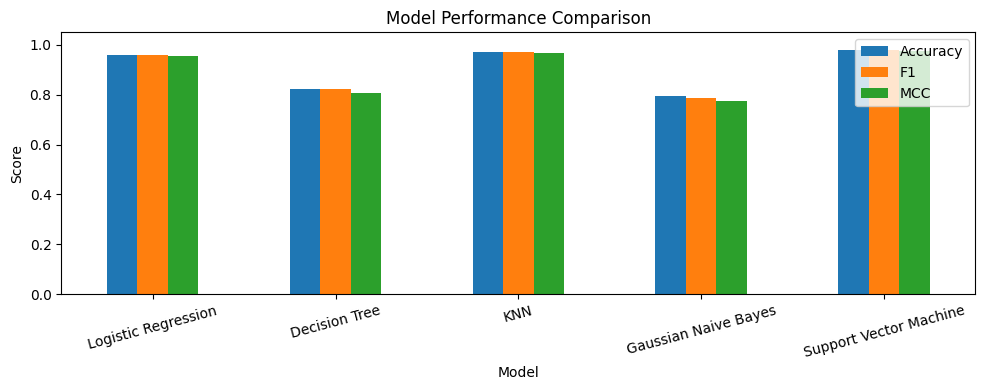

Best model for each metric:


,Model
Accuracy,Support Vector Machine
AUC,Support Vector Machine
Precision,Support Vector Machine
Recall,Support Vector Machine
F1,Support Vector Machine
MCC,Support Vector Machine


Overall best model by MCC: Support Vector Machine


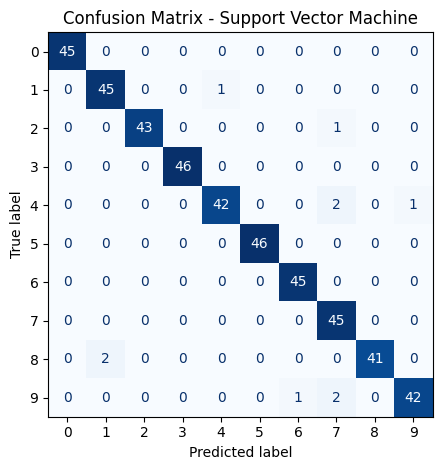

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.96      0.98      0.97        46
           2       1.00      0.98      0.99        44
           3       1.00      1.00      1.00        46
           4       0.98      0.93      0.95        45
           5       1.00      1.00      1.00        46
           6       0.98      1.00      0.99        45
           7       0.90      1.00      0.95        45
           8       1.00      0.95      0.98        43
           9       0.98      0.93      0.95        45

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450

All five models saved successfully.
Test dataset and metrics saved successfully.


In [6]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    ConfusionMatrixDisplay, classification_report
)

FEATURES = [
    f"pixel_r{r}_c{c}"
    for r in range(8)
    for c in range(8)
]
TARGET = "digit"
SEED = 73

data = pd.read_csv("data/uci_digits.csv")

print("Dataset shape:", data.shape)
print("Missing values:", data.isna().sum().sum())
print("Class distribution:")
display(data[TARGET].value_counts().sort_index())
display(data.head())


# 2. Split dataset into training and testing sets

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=SEED,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# 3. Train all five classification models

classifiers = {
    "Logistic Regression": LogisticRegression(C=1.2, max_iter=1600, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=2, random_state=SEED ),
    "KNN": KNeighborsClassifier(n_neighbors=5,weights="distance",algorithm="ball_tree"),
    "Gaussian Naive Bayes": GaussianNB(var_smoothing=1e-8),
    "Support Vector Machine": SVC( C=3.0, kernel="rbf", probability=True, random_state=SEED)
}

models = {}

for name, estimator in classifiers.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("classifier", estimator)
    ])

    pipeline.fit(X_train, y_train)
    models[name] = pipeline
    print("Trained:", name)


# 4. Evaluate all models using six metrics

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(
            y_test, y_prob,
            multi_class="ovr", average="macro"
        ),
        "Precision": precision_score(
            y_test, y_pred,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred,
            average="macro", zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))


# 5. Compare model performance

comparison[["Accuracy", "F1", "MCC"]].plot(
    kind="bar",
    figsize=(10, 4),
    rot=15,
    ylim=(0, 1.05),
    title="Model Performance Comparison"
)

plt.ylabel("Score")
plt.tight_layout()
plt.show()

print("Best model for each metric:")
display(comparison.idxmax().to_frame("Model"))

best_name = comparison["MCC"].idxmax()
print("Overall best model by MCC:", best_name)


# 6. Confusion matrix and classification report

best_predictions = models[best_name].predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=list(range(10)),
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix - " + best_name)
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, best_predictions, zero_division=0
))


# 7. Save models, test dataset and metrics

model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

Path("results").mkdir(exist_ok=True)

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

for name, filename in model_files.items():
    joblib.dump(
        models[name],
        model_dir / filename,
        compress=3
    )

test_data = X_test.copy()
test_data[TARGET] = y_test

test_data.to_csv("test_data.csv", index=False)
comparison.reset_index().to_csv(
    "results/metrics.csv", index=False
)

print("All five models saved successfully.")
print("Test dataset and metrics saved successfully.")
